In [1]:
import numpy as np
import scipy.stats
import scipy.integrate

import matplotlib.pyplot as plt

In [2]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

In [3]:
def reject_sample(distr,prop_distr,M,n): #distr and prop_distr must be in the style of scipy.stats.DISTRIBUTION s.t. .rvs & .pdf is valid calls
    
    us=np.random.uniform(size=n) #uniformly sampled points
    x_i=prop_distr.rvs(size=n) #randomly generated points sampling the proposed distribution
    accepted=np.zeros_like(us)
    
    for i, u in enumerate(us):

        if u*M*prop_distr.pdf(x_i[i]) < distr.pdf(x_i[i]): #check whether point x_i is rejected or not, rescaling with M*prop_distr so u is uniformly sampling between 0 and M*prop_distr
            accepted[i]=1


        
    return us, x_i, accepted

def integrate_elegant(distr, lower, upper):
    I,err=scipy.integrate.quad(distr.pdf,lower,upper)
    return I,err


def integrate_with_sampling(x_i,accept,lower, upper,):

    accepted = accept.astype(bool)
    mask = accepted & (lower <= x_i) & (x_i <= upper)
    return np.sum(mask) / np.sum(accepted)
    

def test_different_distributions(distrs, prop_distr, names, N, lower=-1,upper=5):

    #prop_distr=scipy.stats.norm(loc=1,scale=1) #default proposed distribution

    n_distrs = len(distrs)
    ncols = 2
    nrows = int(np.ceil(n_distrs / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 4 * nrows)
    )
    axes = axes.flatten()

    for i,distr in enumerate(distrs): # go through all distributions
        ax = axes[i]
        mesh=np.linspace(lower,upper,100) # support/where we evaluate it
        
        M=1
        dist_y=distr.pdf(mesh)
        prop_dist_y=M*prop_distr.pdf(mesh)
        while np.sum(np.greater_equal(prop_dist_y,dist_y))<len(dist_y): # finds the smallest M for which  M*normal distr is larger than any value of the to be sampled distr
            M+=1
            prop_dist_y=M*prop_distr.pdf(mesh)
            if M>300:
                print("exit loop due to large M, find a better proposal distribution")
                break
           
            

        u_samples,x_samples,accept=reject_sample(distr,prop_distr,M,N)
        ind=np.where(accept >0)
        acceptance_rate=np.sum(accept)/len(accept)
        ax.hist(x_samples[ind],bins=50,density=True,label= f"Rejection sampling with {N} tries, a_rate= {acceptance_rate:.4f}",alpha=0.8)
        ax.plot(mesh, distr.pdf(mesh),label="Original pdf")
        ax.plot(mesh,prop_dist_y,label=f"Proposed distribution with M={M}")
        ax.set_title(names[i])
        ax.set_xlabel("x")
        ax.set_ylabel("$P$")
        ax.legend()

    for ax in axes[n_distrs:]:
        fig.delaxes(ax)
    plt.show()
        
        


    







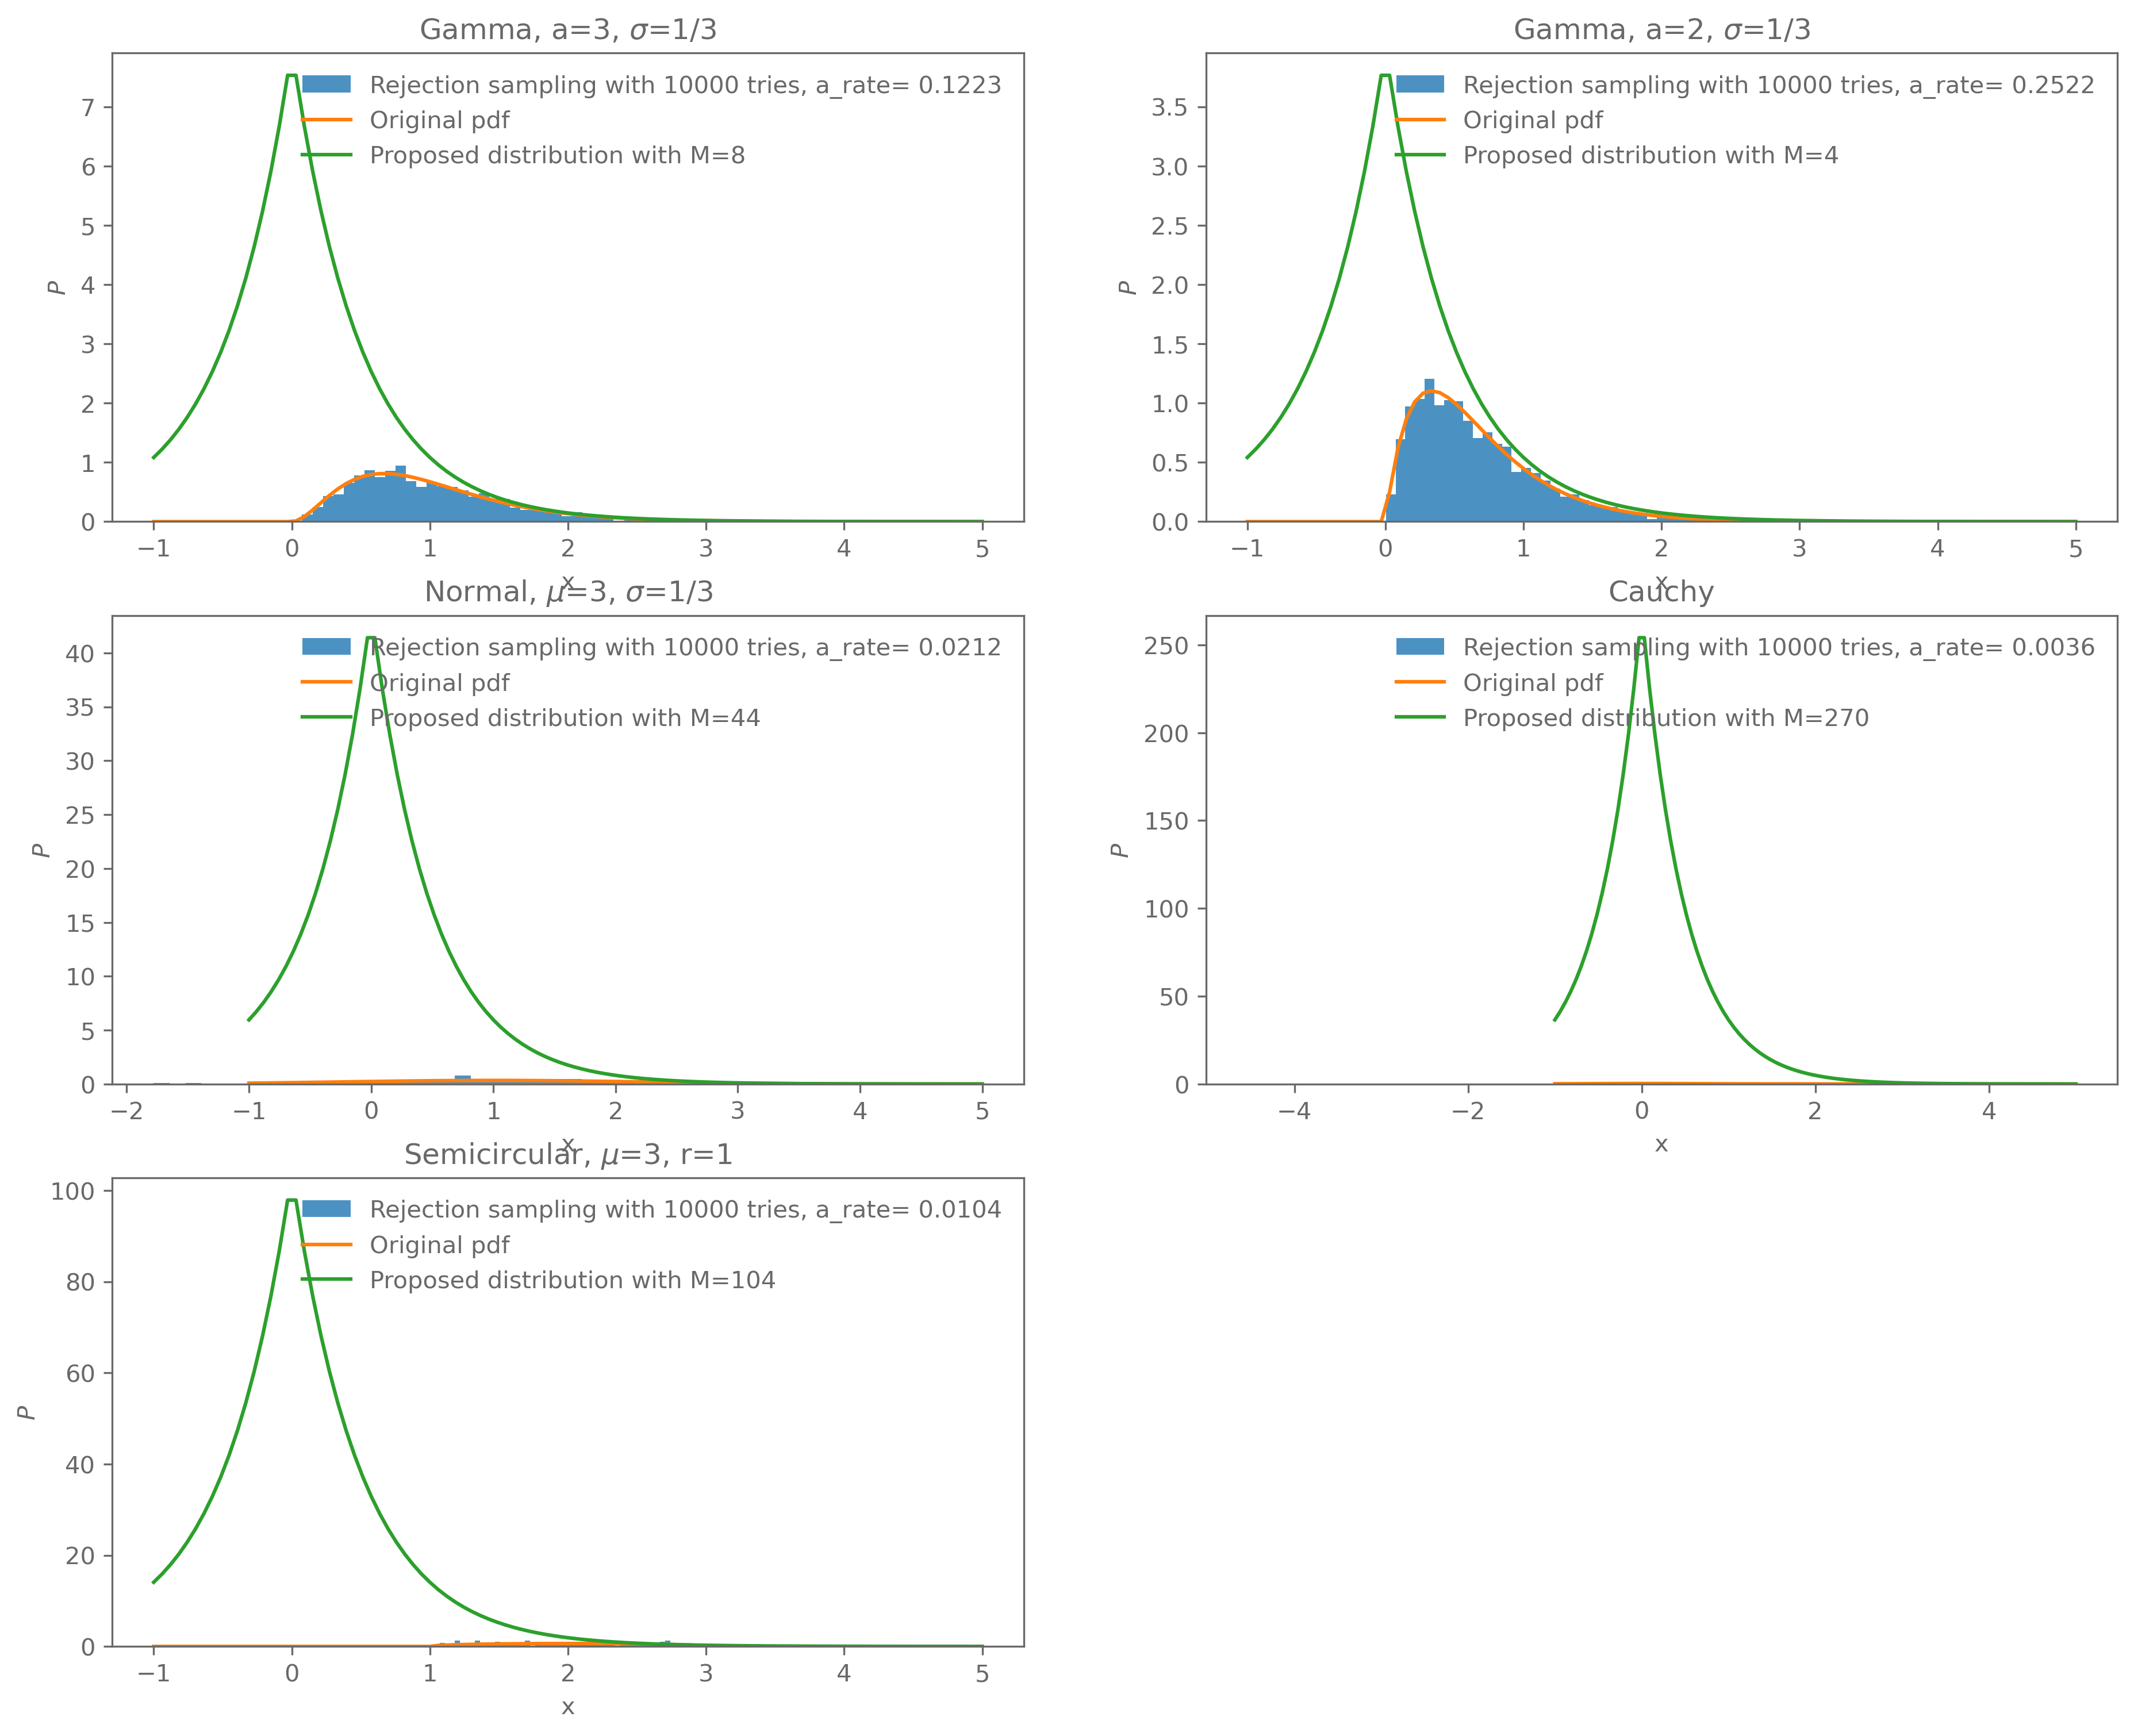

In [4]:
dist1=scipy.stats.gamma(a=3, scale=1/3)
dist2=scipy.stats.gamma(a=2, scale=1/3)
dist3=scipy.stats.norm(loc=1,scale=1.2)
dist4=scipy.stats.cauchy()
dist5=scipy.stats.semicircular(loc=2,scale=1)
names=["Gamma, a=3, $\\sigma$=1/3","Gamma, a=2, $\\sigma$=1/3","Normal, $\\mu$=3, $\\sigma$=1/3","Cauchy", "Semicircular, $\\mu$=3, r=1" ]

prop_dist1=scipy.stats.dgamma(a=1,scale=0.5)
prop_dist2=scipy.stats.norm(loc=1,scale=1)
prop_dist3=scipy.stats.semicircular(loc=2,scale=2)

test_different_distributions([dist1,dist2,dist3,dist4,dist5],prop_dist1,names,10000)

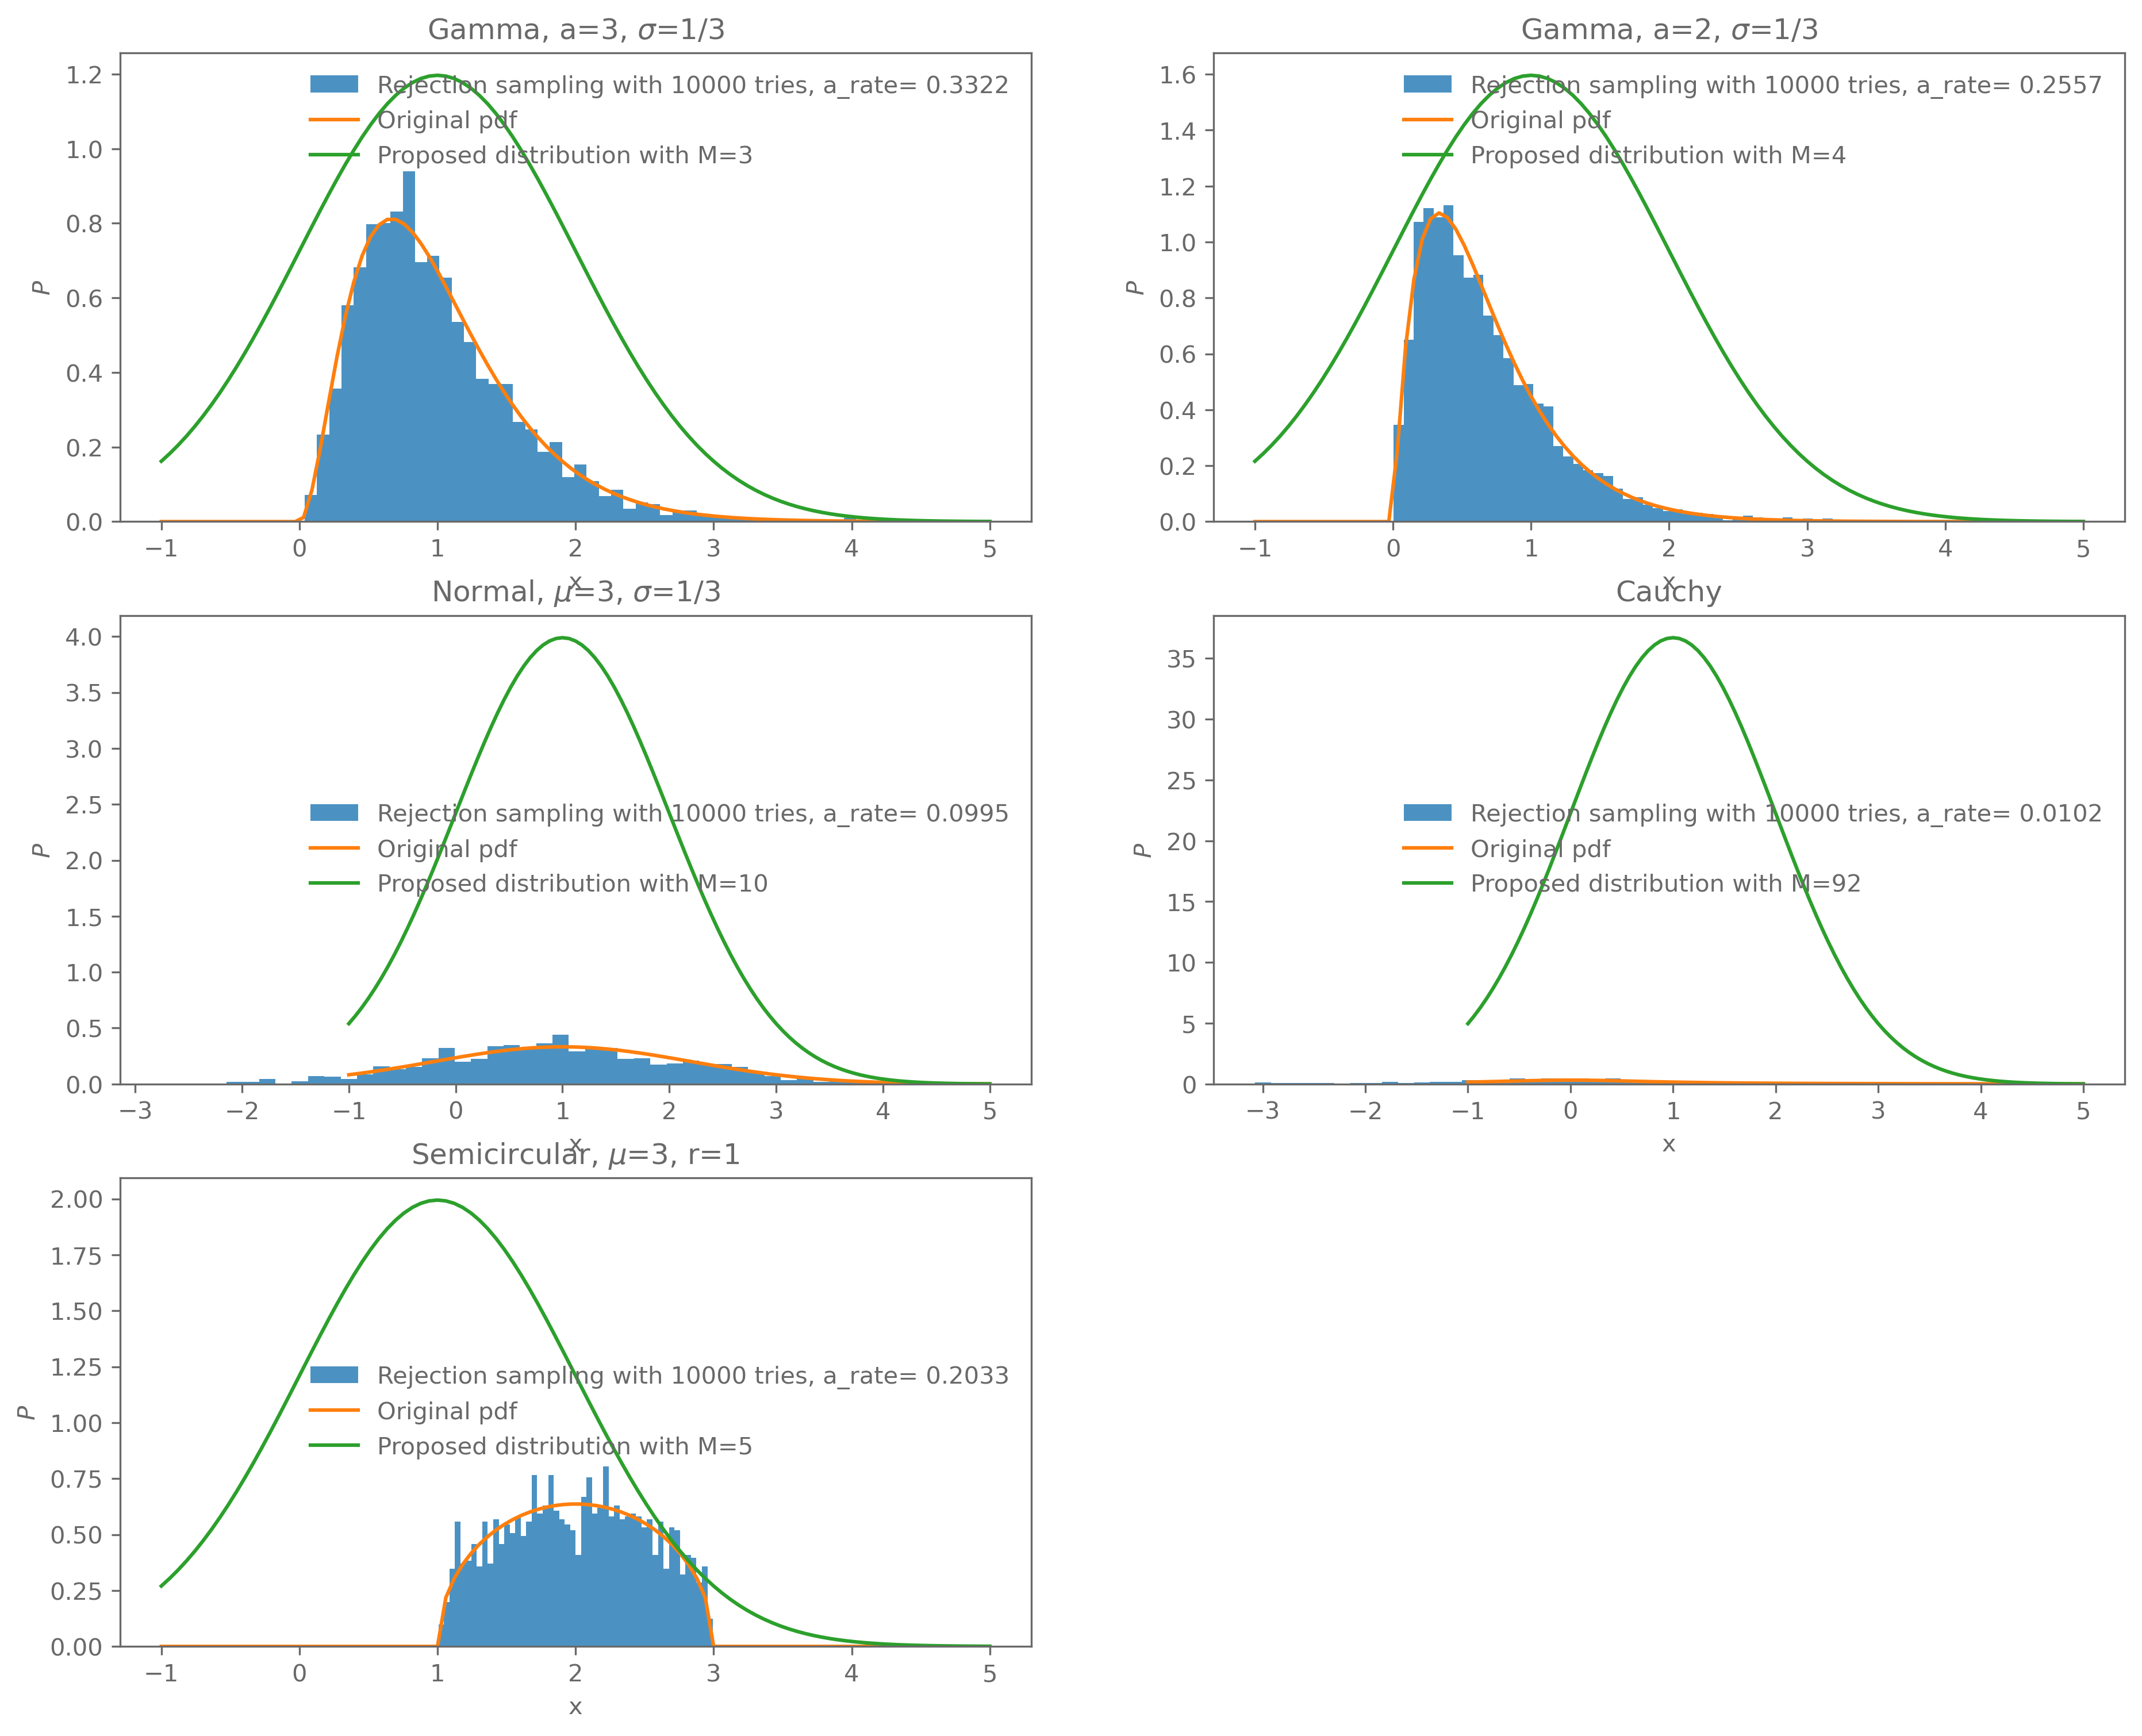

In [5]:
test_different_distributions([dist1,dist2,dist3,dist4,dist5],prop_dist2,names,10000)

exit loop due to large M, find a better proposal distribution


exit loop due to large M, find a better proposal distribution


exit loop due to large M, find a better proposal distribution


exit loop due to large M, find a better proposal distribution


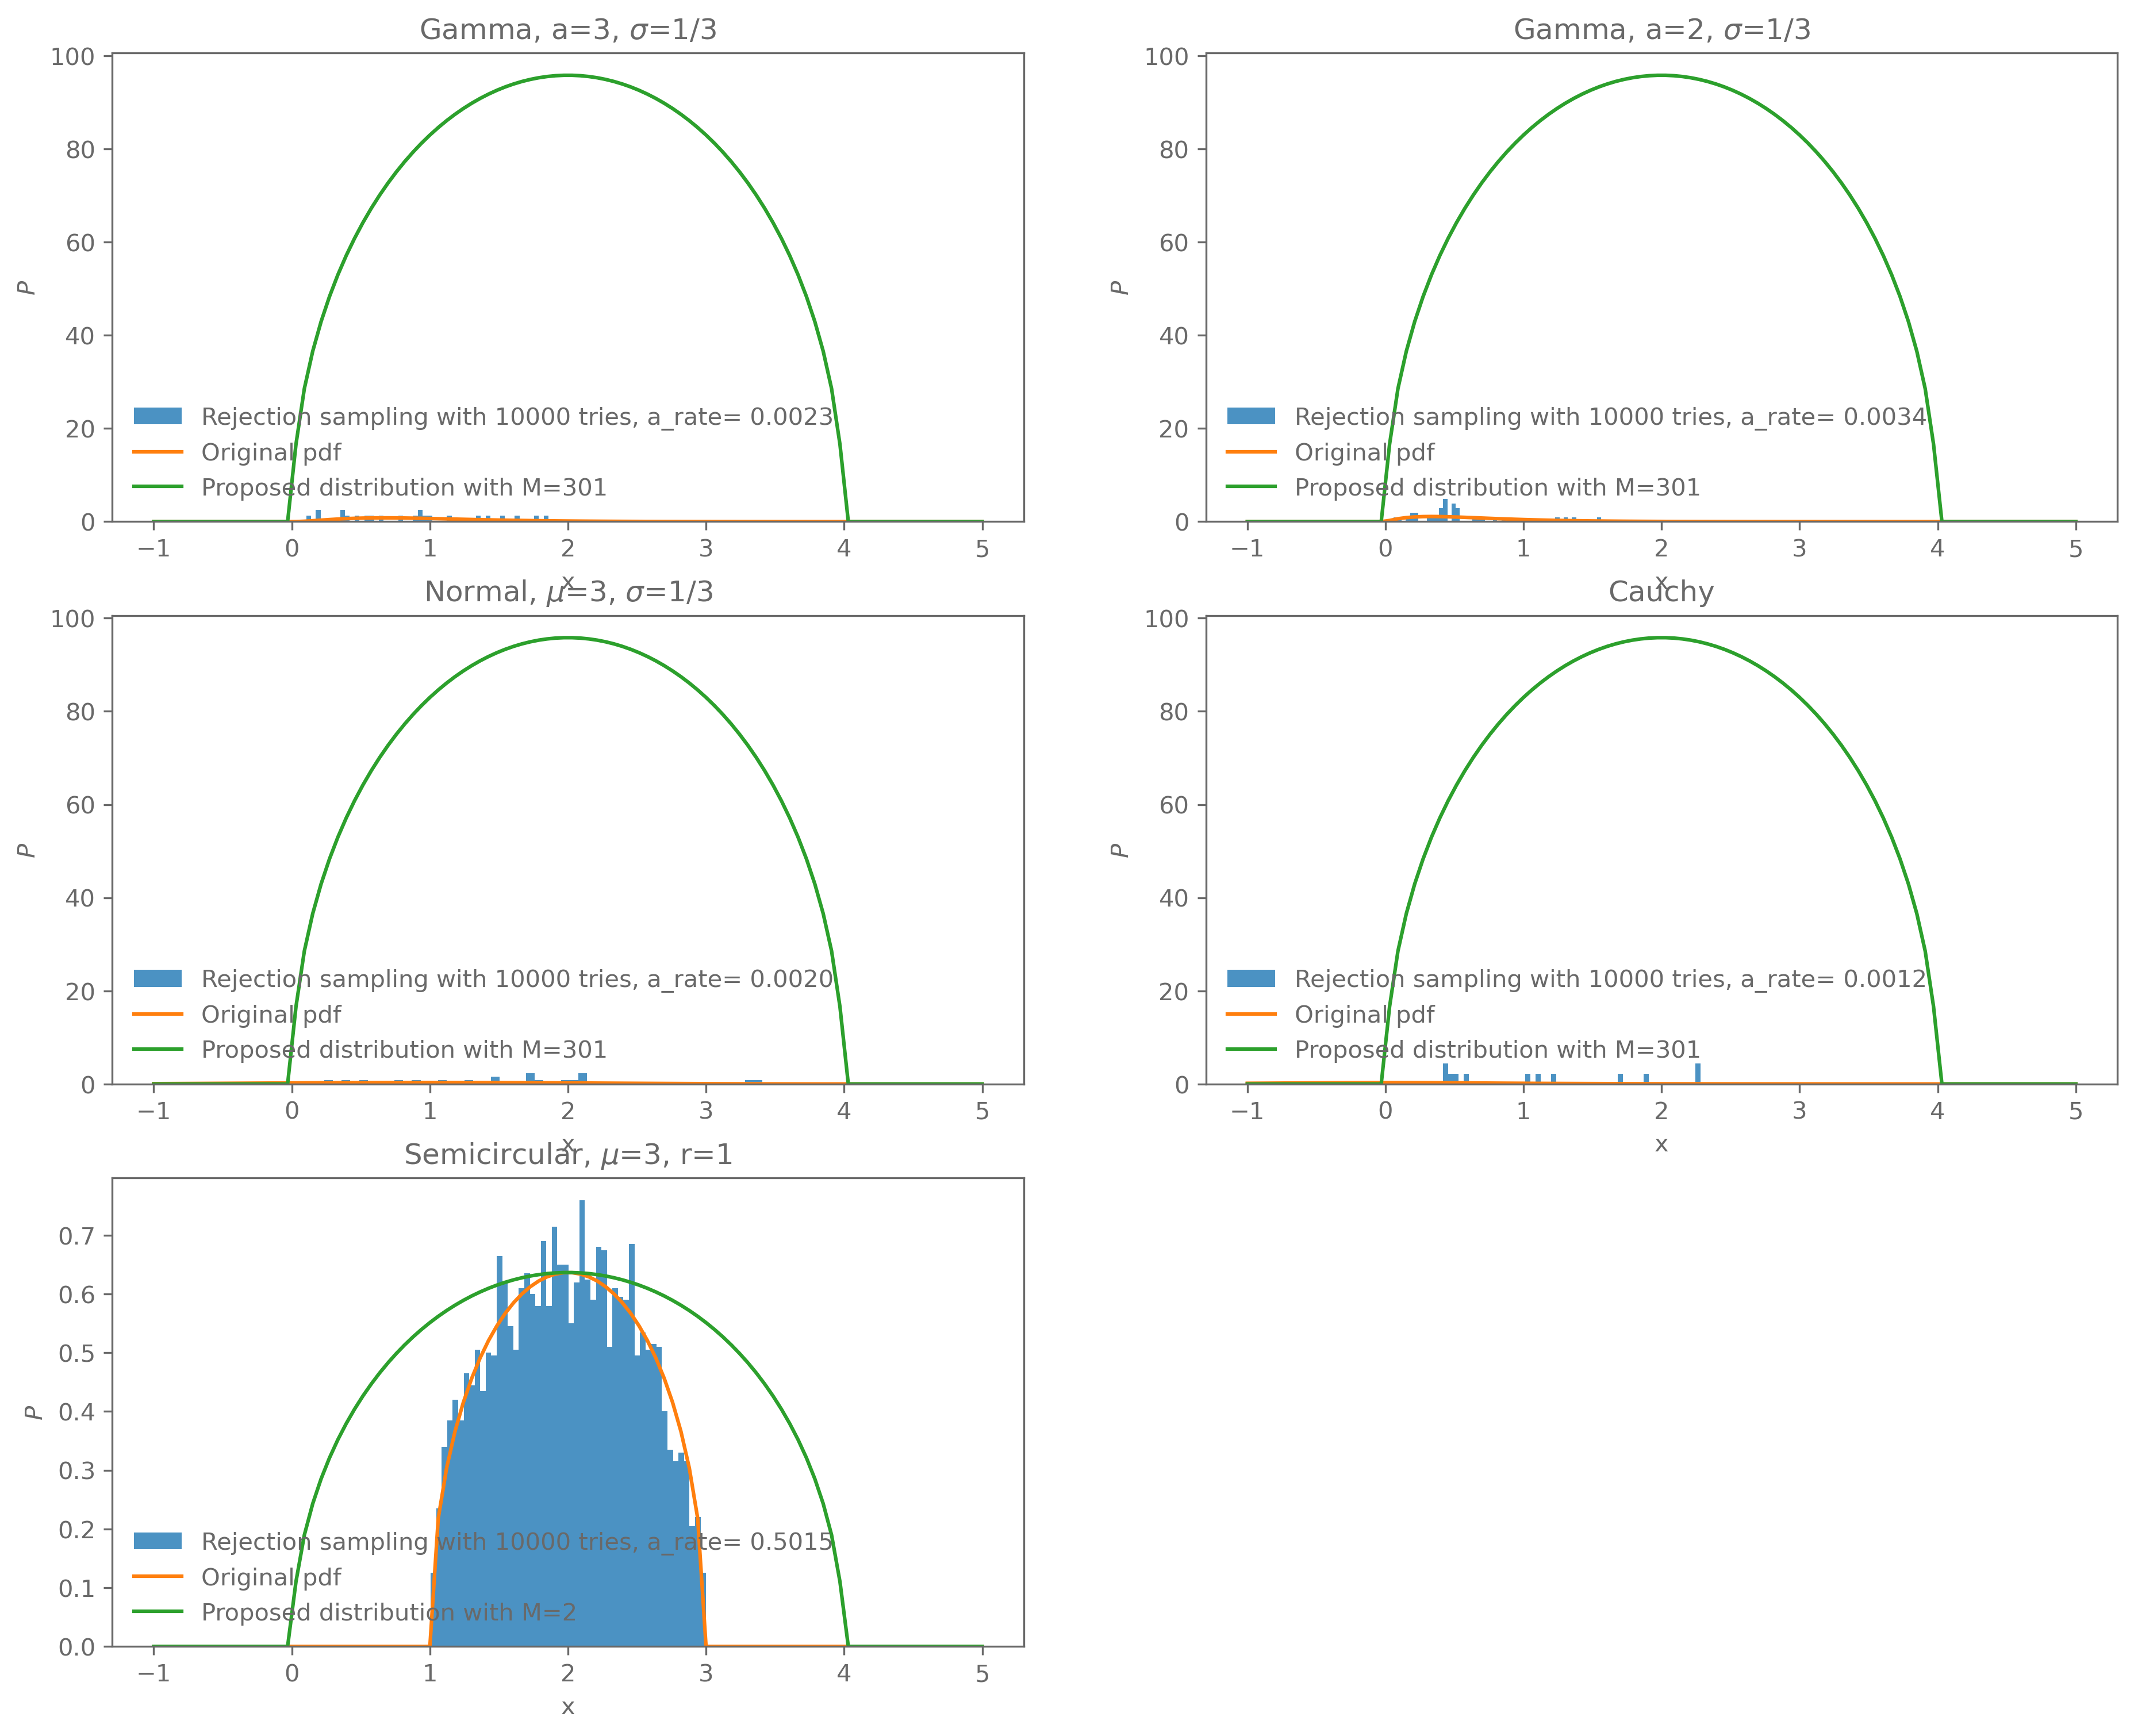

In [6]:
test_different_distributions([dist1,dist2,dist3,dist4,dist5],prop_dist3,names,10000)

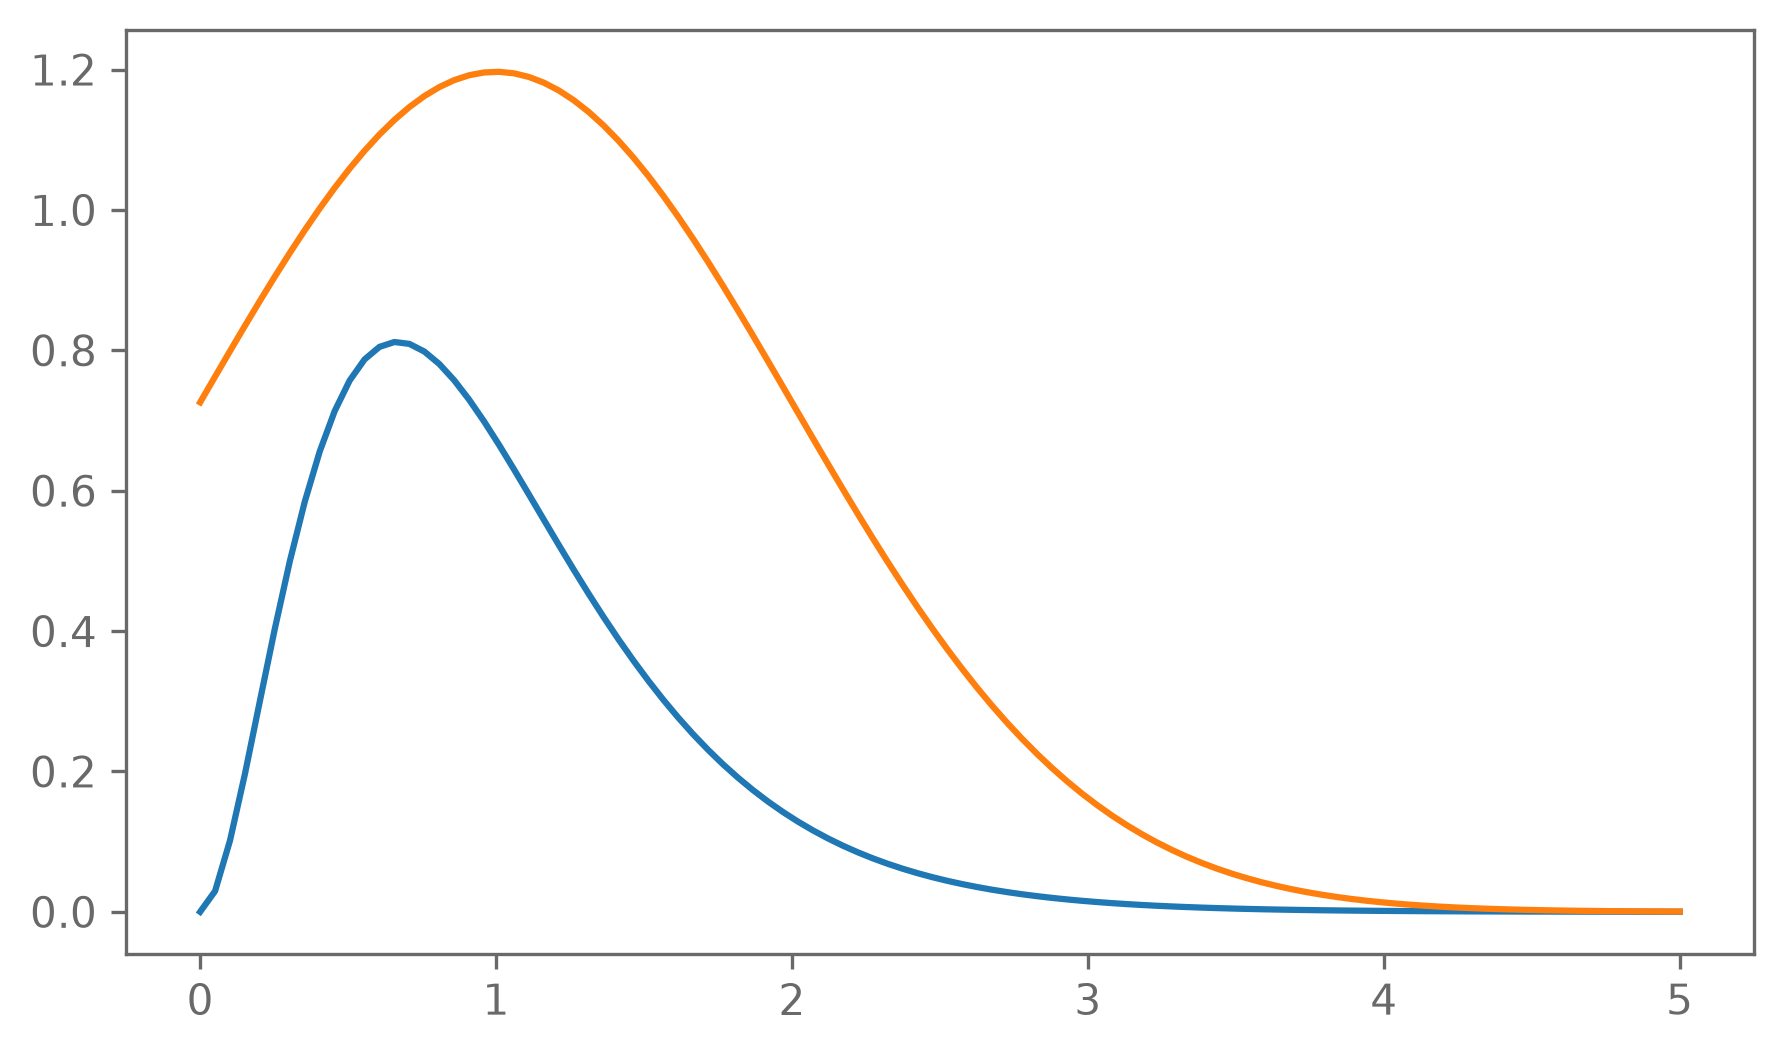

In [5]:
prop_distr=scipy.stats.norm(loc=1,scale=1) #default proposed distribution
M=3
mesh=np.linspace(0,5,100)
plt.plot(mesh,dist1.pdf(mesh))
plt.plot(mesh,M*prop_distr.pdf(mesh))

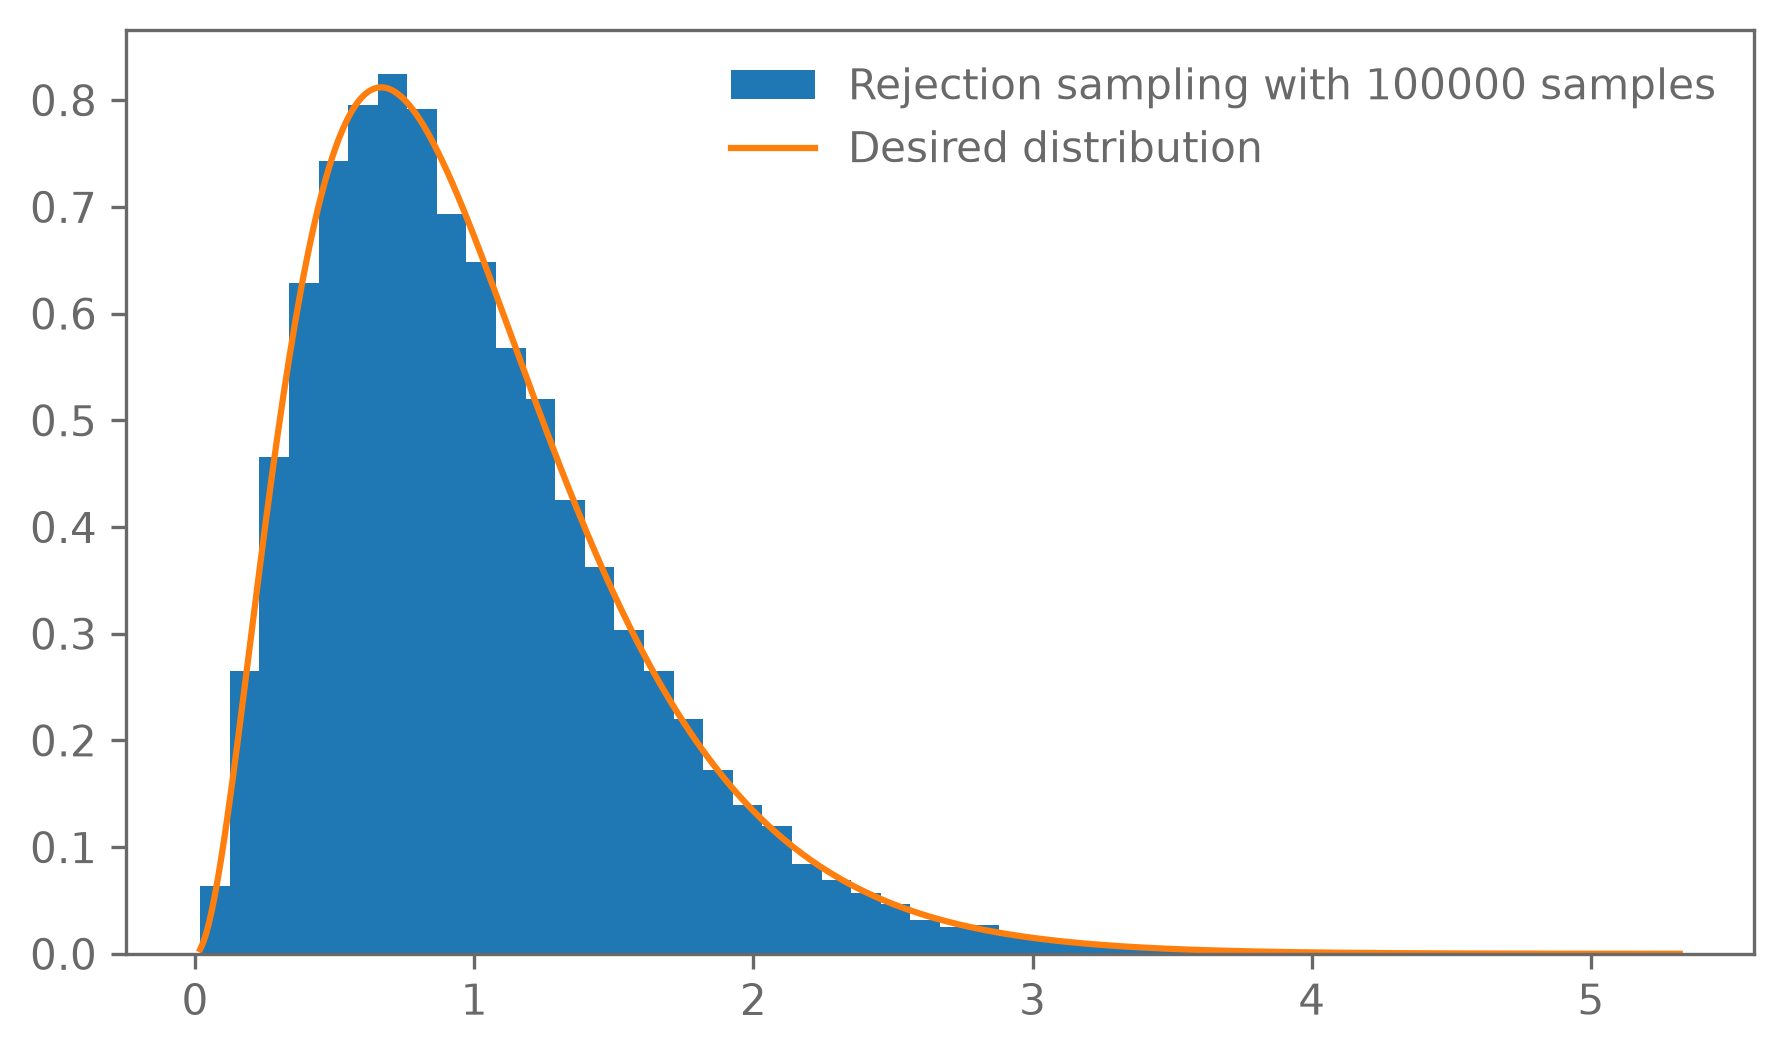

In [6]:
prop_distr=scipy.stats.norm(loc=1, scale=1.3)
distr=scipy.stats.gamma(a=3, scale=1/3)
M=3
N=100000

u_samples,x_samples,accept=reject_sample(distr,prop_distr,M,N)

ind=np.where(accept >0)

plt.hist(x_samples[ind],bins=50,density=True,label= f"Rejection sampling with {N} samples")
mesh=np.linspace(np.min(x_samples[ind]),np.max(x_samples[ind]),500)
plt.plot(mesh,distr.pdf(mesh),label="Desired distribution")
plt.legend()

In [7]:
scipy_I,scipy_err=integrate_elegant(distr,0,5)
MC_I=integrate_with_sampling(x_samples,accept,0,5)
print(f"Scipy integral result: I={scipy_I:.5f}")
print(f"MC integral result with {N} samples: I={MC_I:.10f}")

Scipy integral result: I=0.99996
MC integral result with 100000 samples: I=0.9998804257


### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [8]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

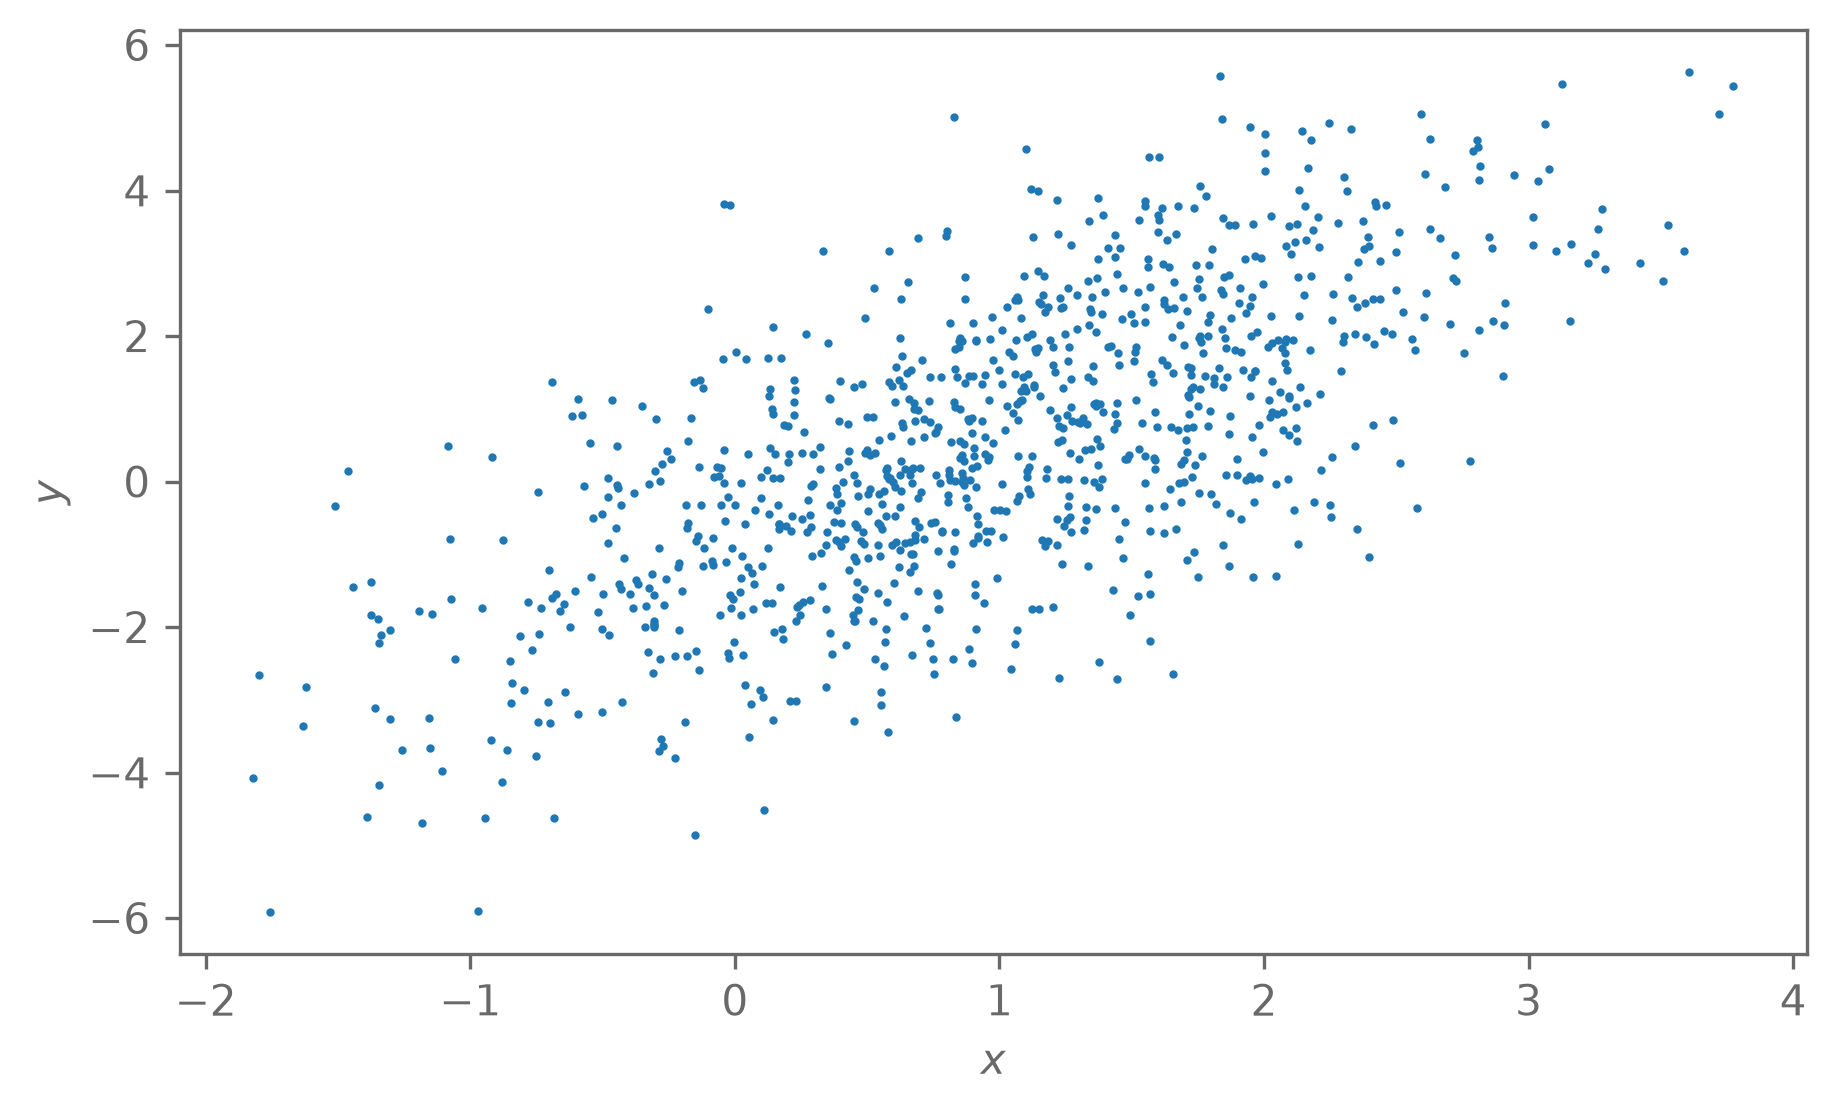

In [9]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");

In [12]:
def MH(target_distr,n,x0):
    sigma_x = 1
    sigma_y = 2
    rho = 0.7
    cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])
    dim=len(x0)
    xs=np.zeros((n+1,dim),dtype=float)
    xs[0,:]=x0
    for i in range (n):
        
        x=scipy.stats.multivariate_normal(mean=x0, cov=cov).rvs() #proposed new x'
        t_prob1=transition_prob(x0,x,cov)
        t_prob0=transition_prob(x,x0,cov)
        p1=target_distr(x)
        p0=target_distr(x0)
        a= (  p1*t_prob0 / (p0*t_prob1))  
        a=min(1,a)
        u=np.random.uniform(low=0,high=1)
        if a>u:
            xs[i+1,:]=x               
            x0=x
        else:
            xs[i+1,:]=x0
    return xs

def  target_distr_wrapper(x): #returns the pdf of the target_distr in d-dimensions at position x, target_distr here is a gamma distribution in all dimensions
    p=np.zeros_like(x, dtype=float)
    for dim,elt in enumerate(x):
        p[dim]=target_distr.pdf(elt)
    return np.prod(p)

def transition_prob(a,b,cov): #returns prob of b given a as parameter (mean here)
    return scipy.stats.multivariate_normal(mean=a, cov=cov).pdf(b) #transition prob uses a multivariate normal distr


def target_distr_wrapper_norm(x):
    sigma_x = 1
    sigma_y = 2
    rho = 0.7
    cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])
    return np.prod(scipy.stats.multivariate_normal(mean=[1,1], cov=cov).pdf(x))

In [6]:
target_distr_wrapper([1,1])

np.float64(0.4517525841974439)

In [13]:
target_distr=scipy.stats.gamma(a=3,scale=1/3)
# proposal_distr=scipy.stats.multivariate_normal(cov=cov)

#target_distr_wrapper(target_distr,[1,2])
res=MH(target_distr_wrapper,10000,[0,0])



/tmp/ipykernel_119/4040218347.py:17: RuntimeWarning: invalid value encountered in scalar divide
  a= (  p1*t_prob0 / (p0*t_prob1))
/tmp/ipykernel_119/4040218347.py:17: RuntimeWarning: divide by zero encountered in scalar divide
  a= (  p1*t_prob0 / (p0*t_prob1))


In [14]:
res_norm=MH(target_distr_wrapper_norm,10000,[0,0])

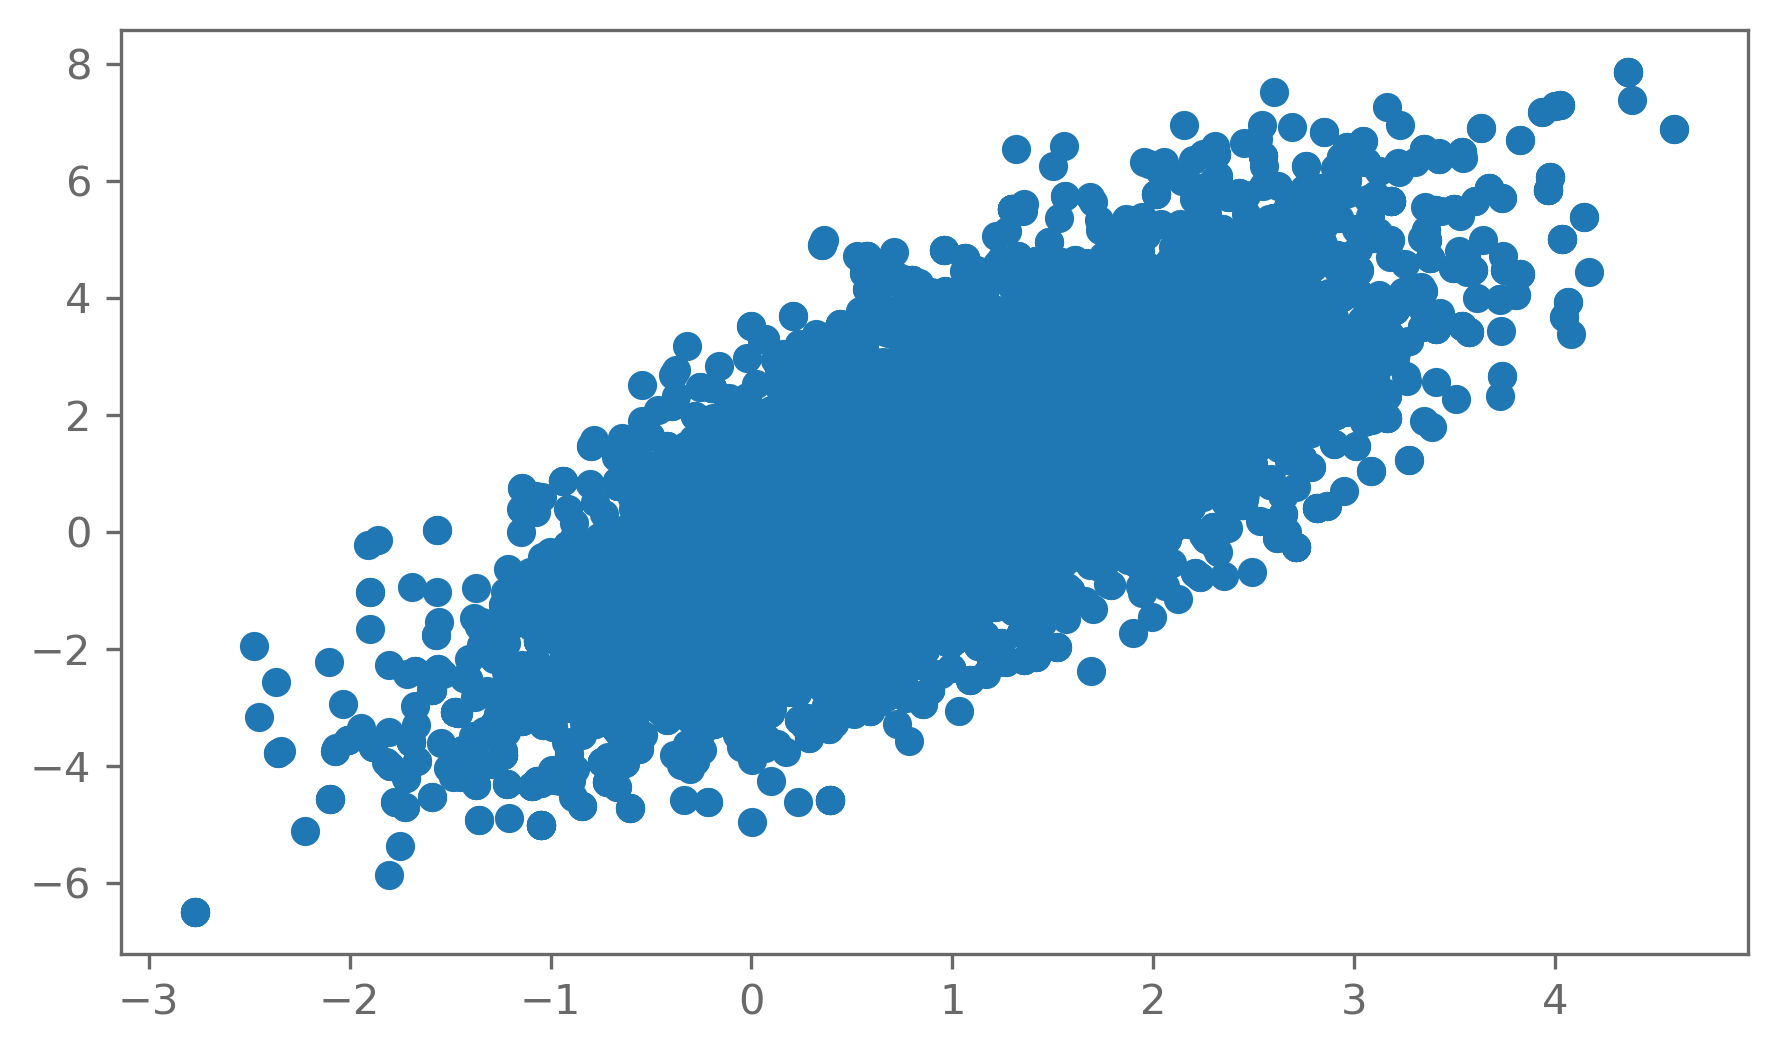

In [15]:
plt.scatter(*res_norm.T)

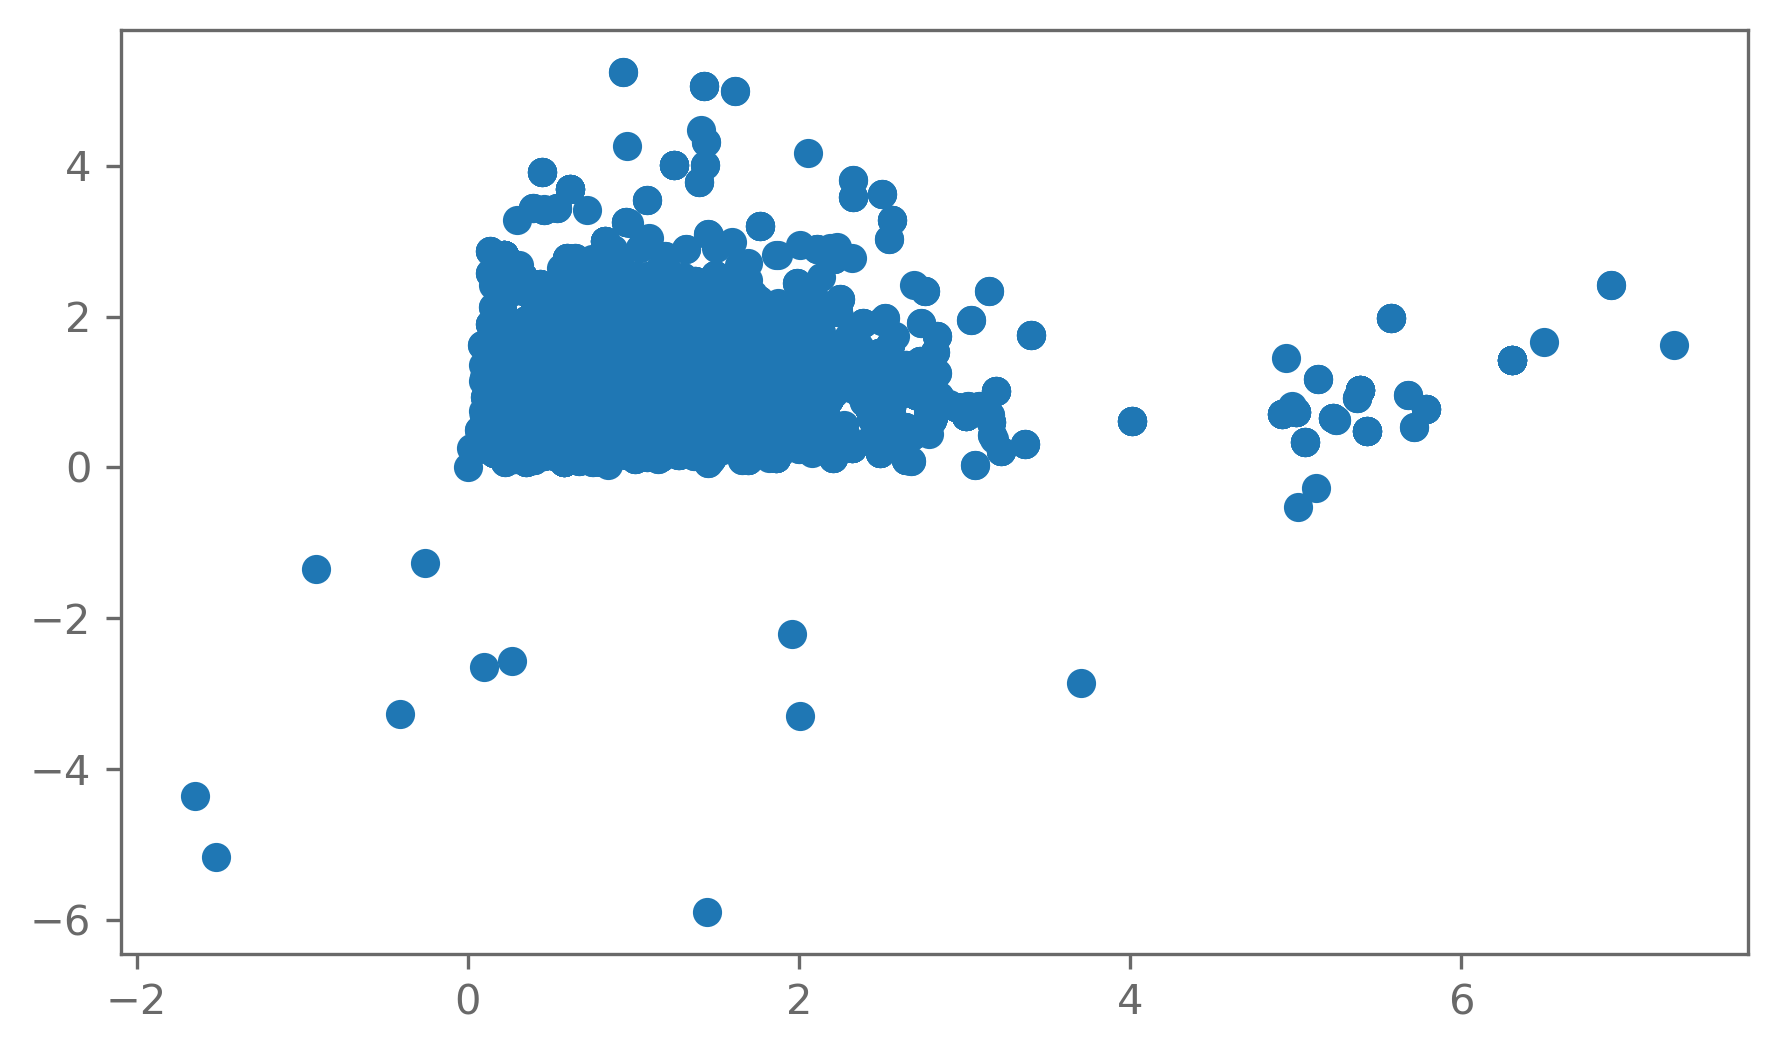

In [16]:
plt.scatter(*res.T)

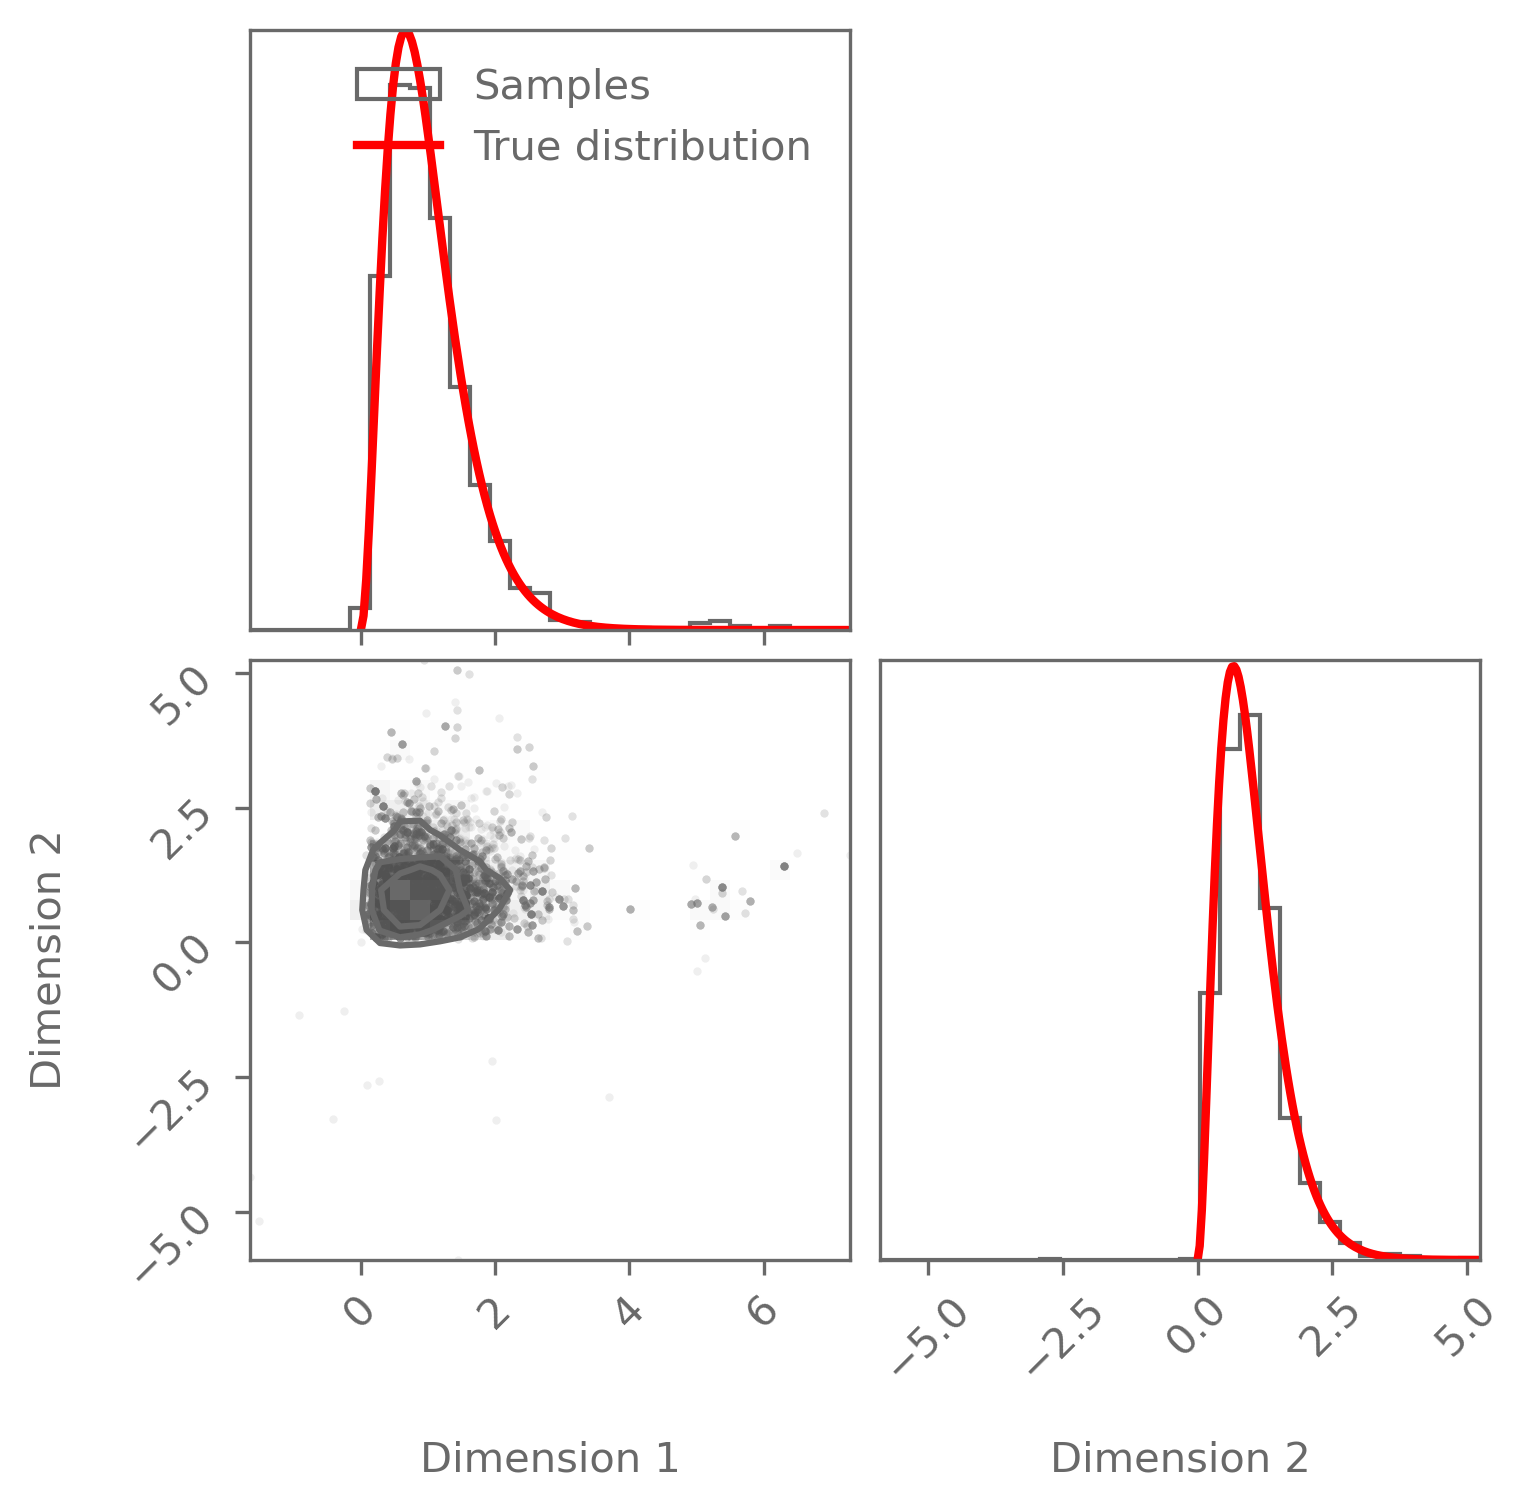

In [17]:
import corner

var_names=["Dimension 1", "Dimension 2"]

fig=corner.corner(res,bins=30,hist_kwargs={"density": True, "label": "Samples"}, labels=var_names)
axes = np.array(fig.axes).reshape((2, 2))

xgrid = np.linspace(0, 20, 500)

# Gamma marginal for x1
axes[0,0].plot(
    xgrid,
    target_distr.pdf(xgrid),
    color="red",
    lw=2,
    label="True distribution"
)

# Gamma marginal for x2
axes[1,1].plot(
    xgrid,
    target_distr.pdf(xgrid),
    color="red",
    lw=2
)
axes[0,0].legend(loc="upper right")

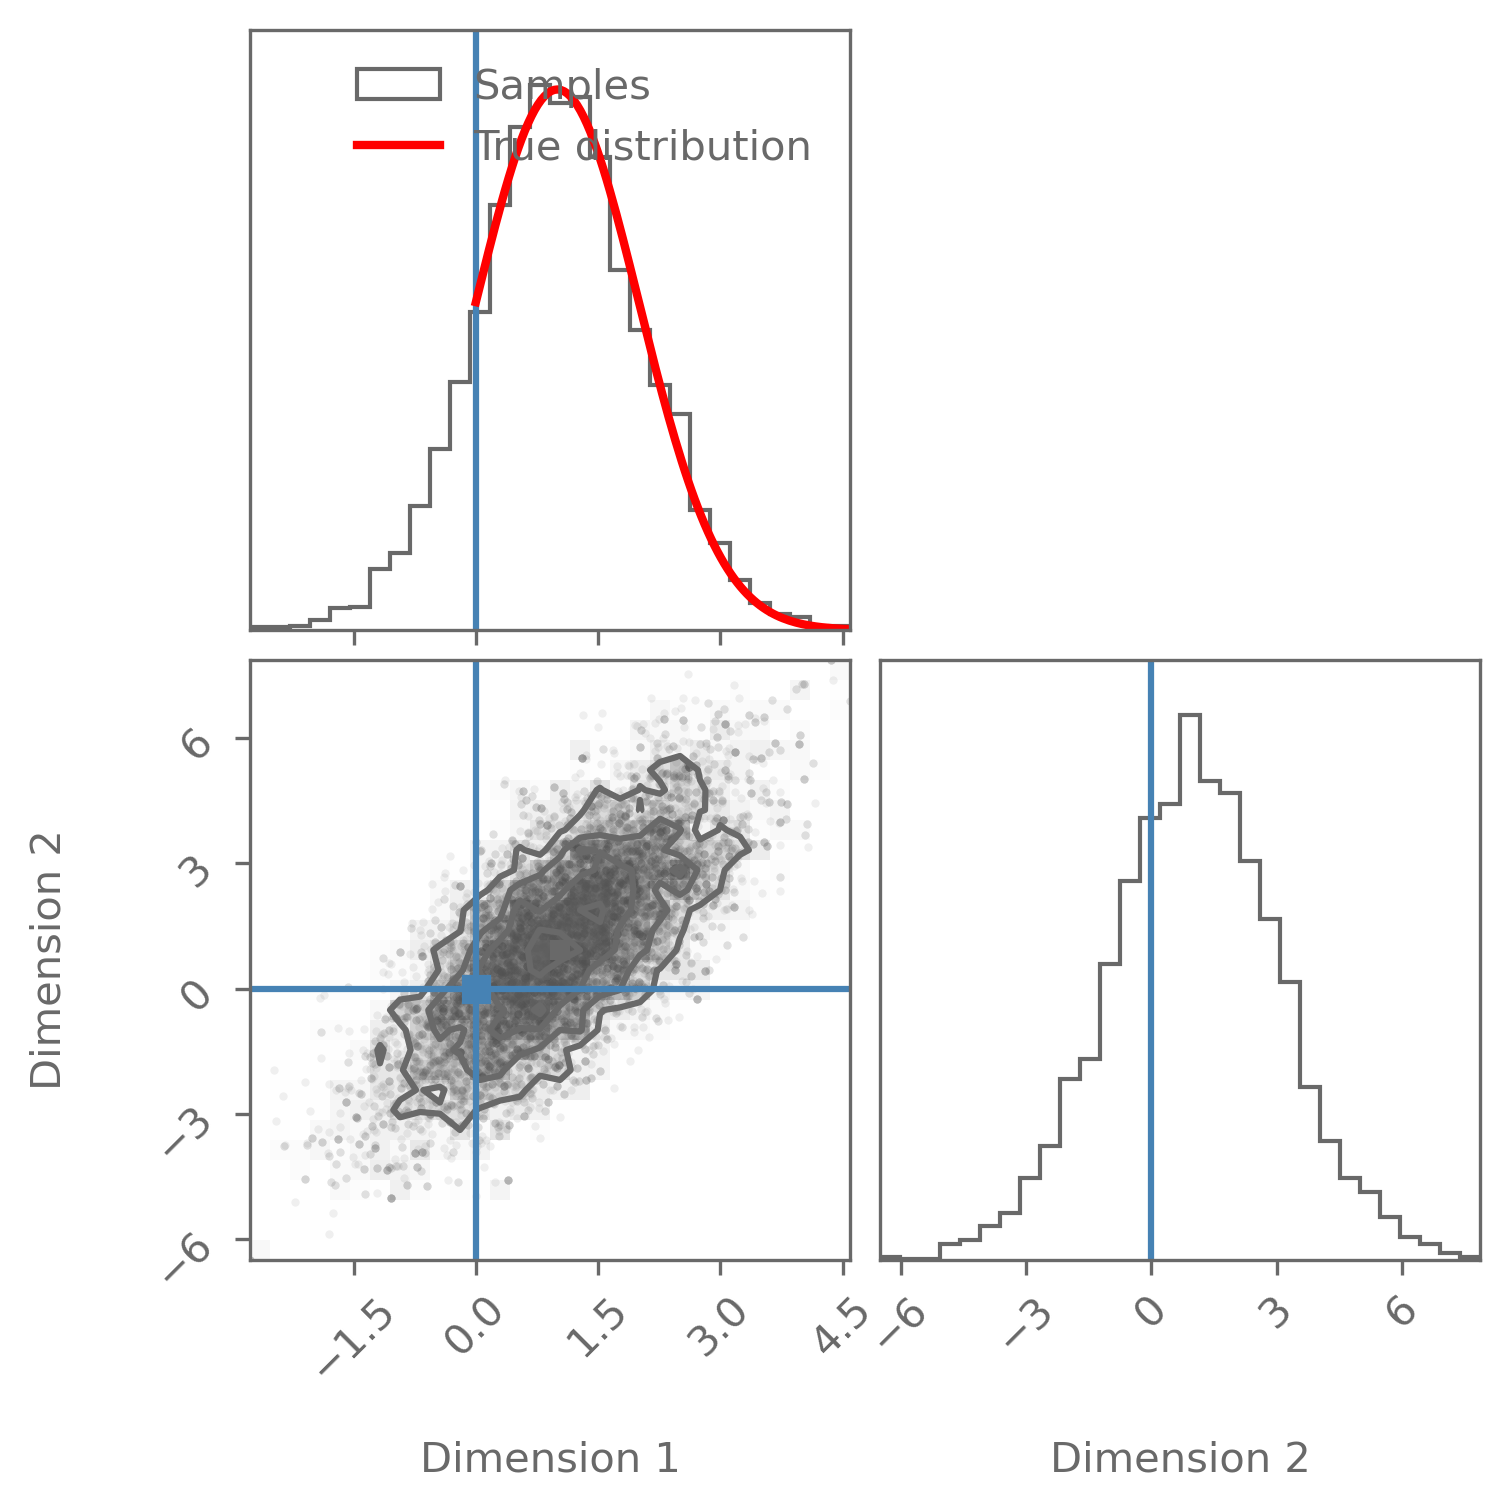

In [22]:
var_names=["Dimension 1", "Dimension 2"]


fig=corner.corner(res_norm,bins=30,hist_kwargs={"density": True, "label": "Samples"}, truths=[0,0], labels=var_names)
axes = np.array(fig.axes).reshape((2, 2))

xgrid = np.linspace(0, 20, 500)

# Gamma marginal for x1
axes[0,0].plot(
    xgrid,
    scipy.stats.norm(loc=1).pdf(xgrid),
    color="red",
    lw=2,
    label="True distribution"
)

# # Gamma marginal for x2
# axes[1,1].plot(
#     xgrid,
#     target_distr.pdf(xgrid),
#     color="red",
#     lw=2
# )
axes[0,0].legend(loc="upper right")

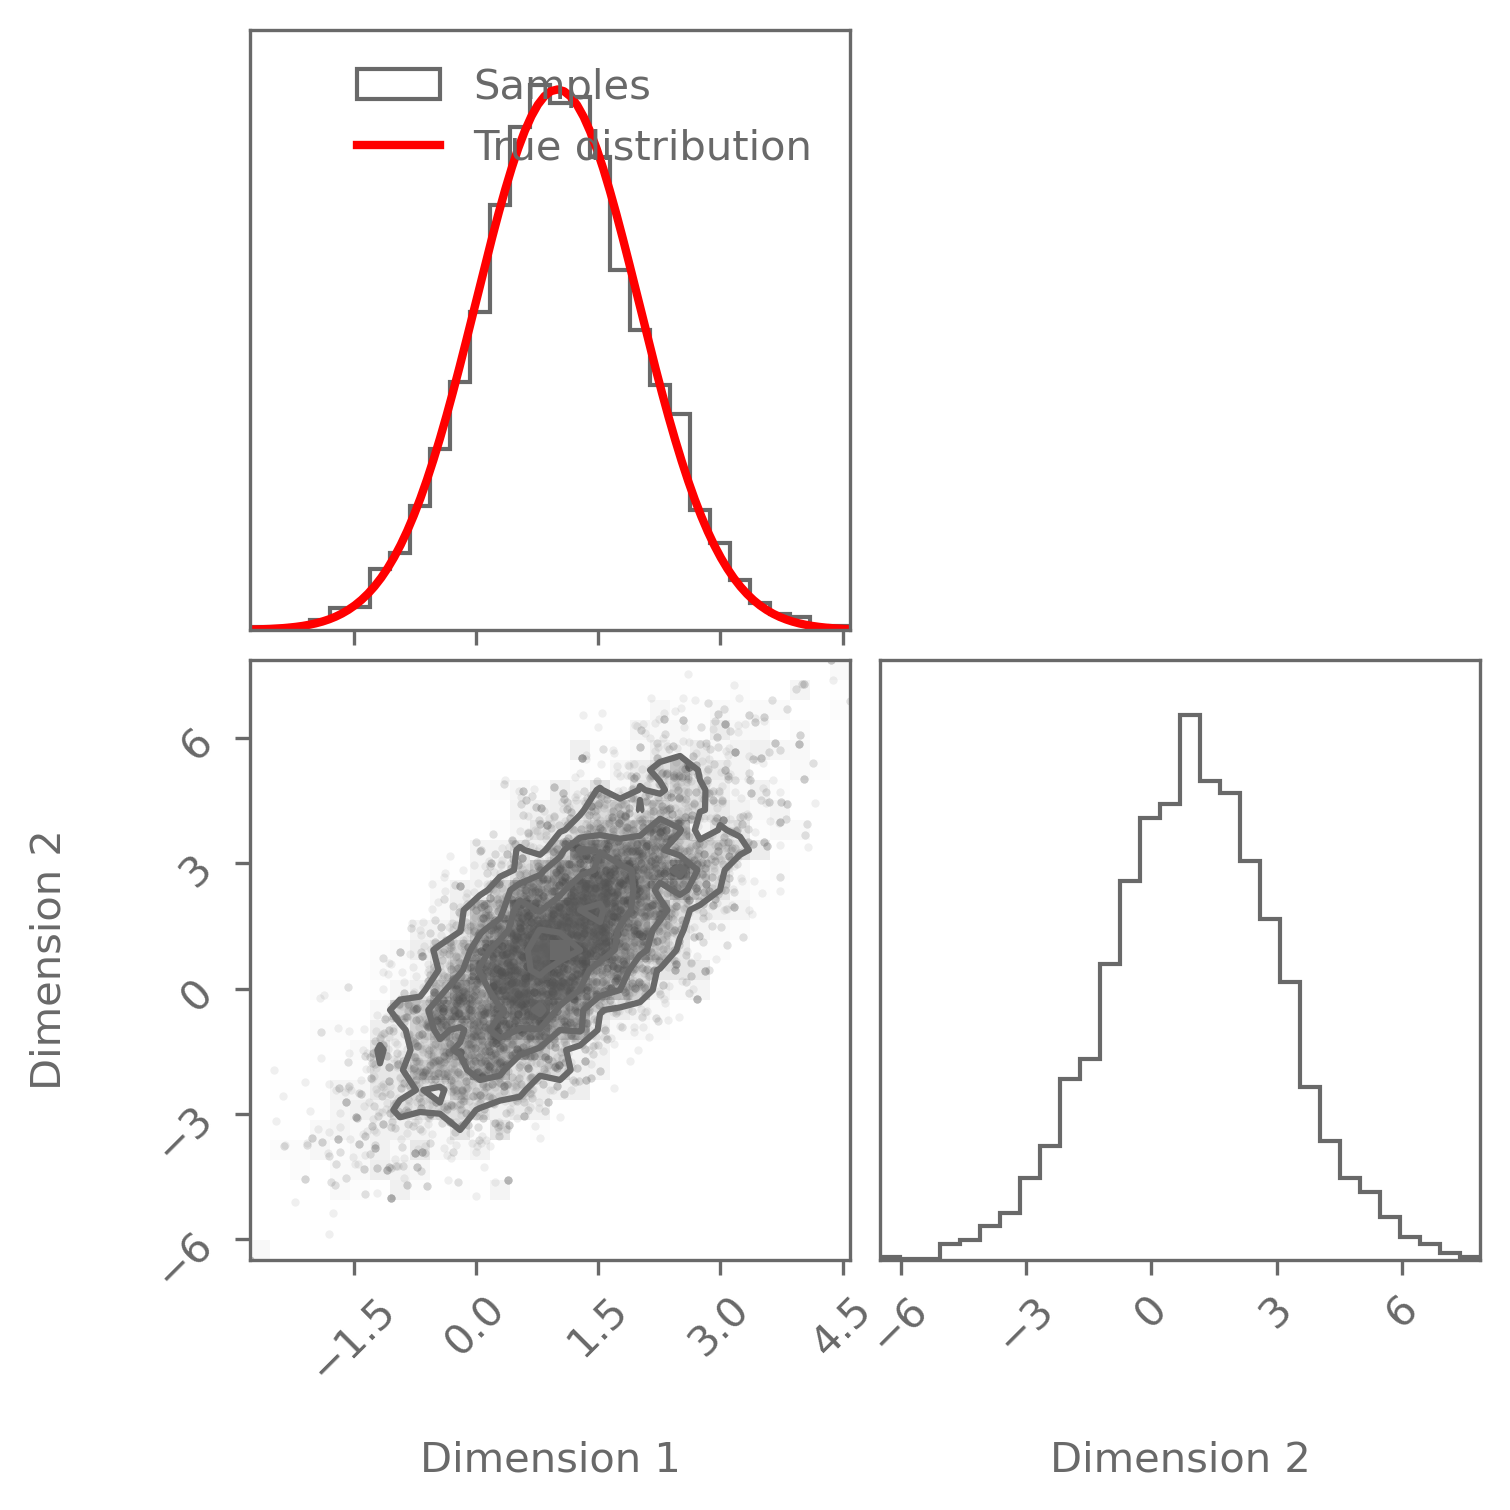

In [26]:
x0=[-5,10]
res_norm2=MH(target_distr_wrapper_norm,10000,x0)

var_names=["Dimension 1", "Dimension 2"]


fig=corner.corner(res_norm,bins=30,hist_kwargs={"density": True, "label": "Samples"}, truths=x0, labels=var_names)
axes = np.array(fig.axes).reshape((2, 2))

xgrid = np.linspace(-20, 20, 500)

# Gamma marginal for x1
axes[0,0].plot(
    xgrid,
    scipy.stats.norm(loc=1).pdf(xgrid),
    color="red",
    lw=2,
    label="True distribution"
)

# # Gamma marginal for x2
# axes[1,1].plot(
#     xgrid,
#     target_distr.pdf(xgrid),
#     color="red",
#     lw=2
# )
axes[0,0].legend(loc="upper right")